# Base-model controlled evaluation

Evaluate the base DeepSeek model on the final test set at 0 and 2 `Wait` continuations. The evaluator uses the same prompt, answer extraction, token limits, batch size, and scoring logic as the adapter notebook.

**Upload required:** `test.json`. `train.json` is optional and only displayed for its size. A T4 GPU is recommended; CPU fallback is supported but slow.


## 1. Install the inference dependencies

This cell installs the libraries needed to load the model, display progress with an ETA, and create plots.


In [1]:
!pip -q install -U transformers accelerate huggingface_hub matplotlib tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 113.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 60.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 123.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 8.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.


## 2. Set paths, device, and reproducibility settings

Colab accepts a flat upload to `/content` or the repository folder layout. Model files are cached separately from the results.


In [2]:
import hashlib, json, os, re, time
from decimal import Decimal, InvalidOperation
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from huggingface_hub import snapshot_download
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

ROOT = Path('/content')
PACKAGE_DIR = ROOT / 'budget-force-reasoning'
MODEL_ID = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B'
ARTIFACT_DIR = next((path for path in (ROOT/'base', PACKAGE_DIR/'base') if path.is_dir()), ROOT)
WEIGHTS_DIR = ARTIFACT_DIR / 'weights'
PLOTS_DIR = ARTIFACT_DIR / 'plots'
RESULTS_DIR = ARTIFACT_DIR / 'results'
for directory in (WEIGHTS_DIR, PLOTS_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
MODEL_DIR = WEIGHTS_DIR / 'base_model_weights'
MODEL_LABEL = 'Base model'
RESULT_STEM = 'base'
SEED = 42
torch.manual_seed(SEED)

def find_input(filename):
    candidates = [ROOT / filename, ROOT / 'base' / filename, PACKAGE_DIR / 'base' / filename, Path.cwd() / filename]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Upload {filename} to /content or /content/base.')

TEST_PATH = find_input('test.json')
TRAIN_PATH = next((p for p in [ROOT/'train.json', ROOT/'base'/'train.json', PACKAGE_DIR/'base'/'train.json'] if p.is_file()), None)
GPU_AVAILABLE = torch.cuda.is_available()
DEVICE = torch.device('cuda' if GPU_AVAILABLE else 'cpu')
print('Model:', MODEL_ID)
print('Test file:', TEST_PATH)
print('GPU available:', GPU_AVAILABLE)
if GPU_AVAILABLE:
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU fallback selected; expect inference to take substantially longer.')


Model: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B
Test file: /content/test.json
GPU available: True
GPU: Tesla T4


## 3. Load and validate the test data

This experiment needs only the held-out test records. The optional training file is never used for fitting or selection.


In [3]:
def load_test(path):
    rows = json.loads(path.read_text(encoding='utf-8'))
    required = {'id', 'x_i', 'y_i', 'topic'}
    if not isinstance(rows, list) or not rows:
        raise ValueError('test.json must contain a non-empty JSON array.')
    for row in rows:
        missing = required - set(row)
        if missing:
            raise ValueError(f"Record {row.get('id')} is missing fields: {sorted(missing)}")
    return rows

test_rows = load_test(TEST_PATH)
assert len({row['id'] for row in test_rows}) == len(test_rows), 'Duplicate IDs found in test data.'
print('Train size:', len(json.loads(TRAIN_PATH.read_text(encoding='utf-8'))) if TRAIN_PATH else 'not uploaded (optional)')
print('Test size:', len(test_rows))
print('Unique test IDs:', len({row['id'] for row in test_rows}))
TEST_SHA256 = hashlib.sha256(TEST_PATH.read_bytes()).hexdigest()


Train size: not uploaded (optional)
Test size: 90
Unique test IDs: 90


## 4. Download the base model if needed

The public model is cached in `/content/base_model_weights`. The notebook reports an expected download time and reuses the cache on later runs.


In [4]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
if not (MODEL_DIR / 'config.json').is_file():
    print('Downloading base model. ETA: around 5-15 minutes, depending on Colab network speed.')
    snapshot_download(repo_id=MODEL_ID, local_dir=MODEL_DIR, token=os.environ.get('HF_TOKEN'))
else:
    print('Base model is already cached; download ETA: 0 minutes.')


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

## 5. Load the tokenizer and model

The T4 uses FP16. CPU fallback uses FP32. No training or adapter weights are loaded in this baseline.


In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, local_files_only=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'left'
load_options = {'local_files_only': True}
if GPU_AVAILABLE:
    load_options.update(torch_dtype=torch.float16, device_map='auto')
else:
    load_options.update(torch_dtype=torch.float32)
model = AutoModelForCausalLM.from_pretrained(MODEL_DIR, **load_options)
if not GPU_AVAILABLE:
    model.to(DEVICE)
model.eval()
print('Base model loaded in', 'FP16' if GPU_AVAILABLE else 'FP32', 'mode.')


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Base model loaded in FP16 mode.


## 6. Shared generation and scoring procedure

The next code cell is intentionally identical to the one in `budget_forcing/evaluation.ipynb`. It evaluates 0 and 2 `Wait` insertions, with the same 1,024-token reasoning cap and 32-token final-answer allowance. A `Wait` is inserted only after an attempted `<final>` or EOS.


Running 0-wait condition. T4 estimate: 15-25 minutes; progress bar refines the ETA.


waits=0:   0%|          | 0/6 [00:00<?, ?it/s]

Running 2-wait condition. T4 estimate: 30-55 minutes; progress bar refines the ETA.


waits=2:   0%|          | 0/6 [00:00<?, ?it/s]

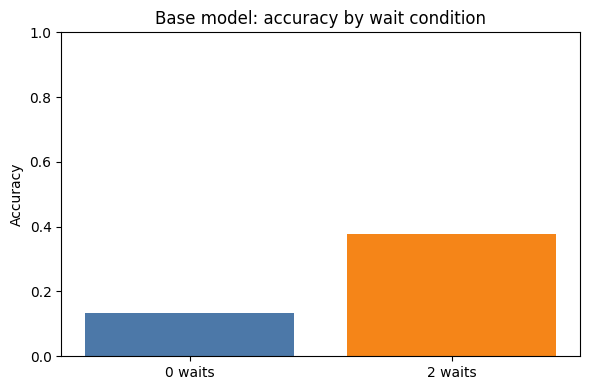

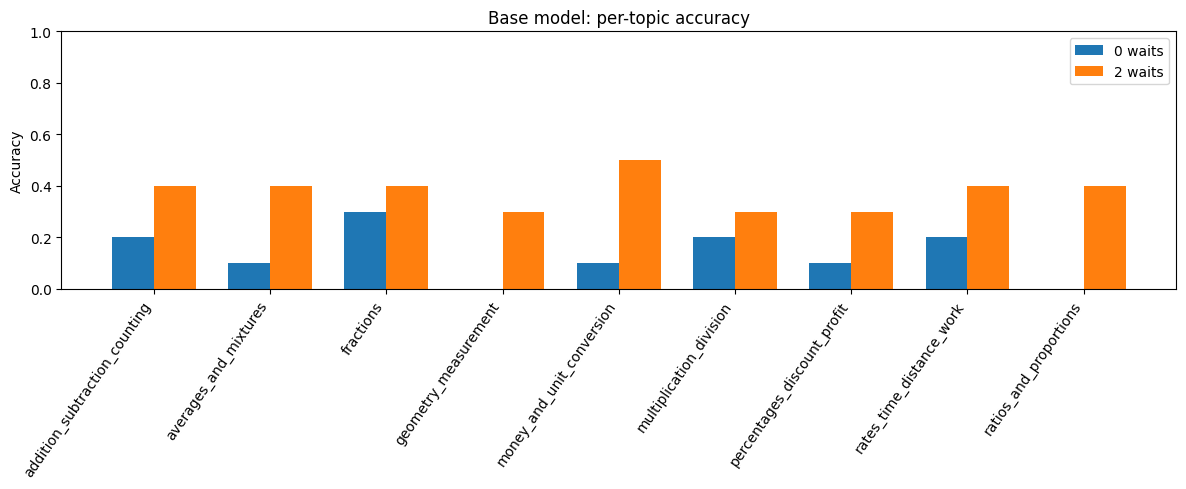

{
  "metadata": {
    "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    "model_variant": "base",
    "test_file": "test.json",
    "test_sha256": "9aba9b0cf8743da2afdcf04031e186536f6789c60b66efeb665b788e8861e5b4",
    "device": "Tesla T4",
    "precision": "float16",
    "batch_size": 16,
    "thinking_budget_tokens": 1024,
    "answer_tokens": 32,
    "wait_conditions": [
      0,
      2
    ],
    "prompt_template": "Question: {question}\\n\\n<think>\\n",
    "runtime_minutes": 16.76259565750758
  },
  "summary": {
    "0": {
      "accuracy": 0.13333333333333333,
      "correct": 12,
      "total": 90,
      "control": 0.0,
      "average_thinking_tokens": 622.2222222222222
    },
    "2": {
      "accuracy": 0.37777777777777777,
      "correct": 34,
      "total": 90,
      "control": 0.0,
      "average_thinking_tokens": 923.4555555555555
    },
    "accuracy_gain_2_vs_0": 0.24444444444444444,
    "two_wait_condition_improved": true
  },
  "per_topic_accuracy": {
    "

In [6]:
# Both notebooks use this exact evaluation procedure. Only the loaded weights differ.
model.config.use_cache = True
model.eval()
BATCH_SIZE = 16
SEGMENT_TOKENS = 1024
THINKING_BUDGET = 1024
ANSWER_TOKENS = 32
FORCING_CONFIGS = (0, 2)

def canonical(value):
    try:
        number = Decimal(str(value).strip().replace(',', '').replace('$', ''))
    except InvalidOperation:
        return None
    if not number.is_finite():
        return None
    text = format(number.normalize(), 'f')
    if '.' in text:
        text = text.rstrip('0').rstrip('.')
    return '0' if text in ('', '-0') else text

def batch_generate(prompts, max_tokens, stop_on_final=False):
    encoded = tokenizer(
        prompts, return_tensors='pt', padding=True, truncation=True,
        max_length=3072
    ).to(model.device)
    options = {
        'do_sample': False,
        'max_new_tokens': max_tokens,
        'pad_token_id': tokenizer.eos_token_id,
        'eos_token_id': tokenizer.eos_token_id,
    }
    if stop_on_final:
        # Stop when the model attempts its final answer; </think> alone is not a stop.
        options.update(stop_strings=['<final>'], tokenizer=tokenizer)
    with torch.inference_mode():
        output = model.generate(**encoded, **options)
    prompt_width = encoded['input_ids'].shape[1]
    eos_ids = {tokenizer.eos_token_id} if isinstance(tokenizer.eos_token_id, int) else set(tokenizer.eos_token_id or [])
    generated = []
    for index in range(len(prompts)):
        token_ids = output[index, prompt_width:].tolist()
        text = tokenizer.decode(token_ids, skip_special_tokens=True)
        generated.append({
            'text': text,
            'natural_stop': '<final>' in text or any(token_id in eos_ids for token_id in token_ids),
        })
    return generated

def split_before_final(text):
    position = text.find('<final>')
    if position >= 0:
        text = text[:position]
    return re.sub(r'\s*</think>\s*$', '', text).rstrip()

def evaluate_configuration(num_waits):
    rows_out = []
    for start in tqdm(range(0, len(test_rows), BATCH_SIZE), desc=f'waits={num_waits}'):
        batch = test_rows[start:start + BATCH_SIZE]
        prefixes = [f"Question: {row['x_i']}\n\n<think>\n" for row in batch]
        reasoning = [''] * len(batch)
        token_counts = [0] * len(batch)
        waits_inserted = [0] * len(batch)
        completed = [False] * len(batch)
        active = list(range(len(batch)))

        # Re-feed the full prefix; insert Wait only after the model attempts <final> or EOS.
        while active:
            prompts = [prefixes[i] + reasoning[i] for i in active]
            allowance = min(SEGMENT_TOKENS, max(THINKING_BUDGET - token_counts[i] for i in active))
            segments = batch_generate(prompts, allowance, stop_on_final=True)
            still_active = []
            for i, generated in zip(active, segments):
                raw = generated['text']
                stopped_on_final = '<final>' in raw
                segment = split_before_final(raw)
                reached_stop = stopped_on_final or generated['natural_stop']
                segment_ids = tokenizer.encode(segment, add_special_tokens=False)
                remaining = THINKING_BUDGET - token_counts[i]
                if len(segment_ids) > remaining:
                    segment_ids = segment_ids[:remaining]
                    segment = tokenizer.decode(segment_ids, skip_special_tokens=True)
                    reached_stop = False
                reasoning[i] += segment
                token_counts[i] += len(segment_ids)

                if not segment_ids and not reached_stop:
                    continue
                if reached_stop and waits_inserted[i] < num_waits and token_counts[i] < THINKING_BUDGET:
                    reasoning[i] += '\nWait\n'
                    waits_inserted[i] += 1
                    still_active.append(i)
                elif reached_stop:
                    completed[i] = True
                elif token_counts[i] < THINKING_BUDGET:
                    still_active.append(i)
            active = still_active

        answer_prompts = [prefixes[i] + reasoning[i] + '\n</think>\n<final>\n' for i in range(len(batch))]
        answer_segments = batch_generate(answer_prompts, ANSWER_TOKENS)
        for i, (row, answer_segment) in enumerate(zip(batch, answer_segments)):
            answer = answer_segment['text']
            numbers = re.findall(r'(?<![\w.])-?\$?[\d,]+(?:\.\d+)?', answer)
            prediction = canonical(numbers[-1]) if numbers else None
            expected = canonical(row['y_i'])
            malformed = prediction is None or '</think>' in reasoning[i] or '<final>' in reasoning[i]
            error_flags = {
                'missing_answer': prediction is None,
                'incomplete_forcing': waits_inserted[i] != num_waits,
                'thinking_budget_exhausted': token_counts[i] >= THINKING_BUDGET and not completed[i],
                'malformed_reasoning': '</think>' in reasoning[i] or '<final>' in reasoning[i],
            }
            rows_out.append({
                'id': row['id'], 'topic': row['topic'], 'expected_answer': expected,
                'extracted_answer': prediction, 'correct': prediction == expected,
                'thinking_tokens': token_counts[i], 'forced_continuations': waits_inserted[i],
                'requested_continuations': num_waits,
                'control': token_counts[i] <= THINKING_BUDGET and completed[i] and waits_inserted[i] == num_waits and not malformed,
                'error_flags': error_flags,
                'trace': '<think>\n' + reasoning[i] + '\n</think>\n<final>\n' + answer,
            })
    return rows_out

RUN_METADATA = {
    'model_id': MODEL_ID,
    'model_variant': 'base_plus_qlora_adapter' if 'ADAPTER_DIR' in globals() else 'base',
    'test_file': TEST_PATH.name,
    'test_sha256': hashlib.sha256(TEST_PATH.read_bytes()).hexdigest(),
    'device': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
    'precision': 'float16' if torch.cuda.is_available() else 'float32',
    'batch_size': BATCH_SIZE,
    'thinking_budget_tokens': THINKING_BUDGET,
    'answer_tokens': ANSWER_TOKENS,
    'wait_conditions': list(FORCING_CONFIGS),
    'prompt_template': 'Question: {question}\\n\\n<think>\\n',
}
if 'ADAPTER_DIR' in globals():
    RUN_METADATA['adapter_config_sha256'] = hashlib.sha256((ADAPTER_DIR/'adapter_config.json').read_bytes()).hexdigest()
    RUN_METADATA['adapter_weights_sha256'] = hashlib.sha256((ADAPTER_DIR/'adapter_model.safetensors').read_bytes()).hexdigest()

evaluation_started = time.time()
predictions = {}
summary = {}
for num_waits in FORCING_CONFIGS:
    estimate = '15-25 minutes' if num_waits == 0 else '30-55 minutes'
    print(f'Running {num_waits}-wait condition. T4 estimate: {estimate}; progress bar refines the ETA.')
    rows = evaluate_configuration(num_waits)
    key = str(num_waits)
    predictions[key] = rows
    summary[key] = {
        'accuracy': sum(row['correct'] for row in rows) / len(rows),
        'correct': sum(row['correct'] for row in rows),
        'total': len(rows),
        'control': sum(row['control'] for row in rows) / len(rows),
        'average_thinking_tokens': sum(row['thinking_tokens'] for row in rows) / len(rows),
    }
    # Save a recoverable partial result after each complete condition.
    (RESULTS_DIR / f'{RESULT_STEM}_budget_results.partial.json').write_text(
        json.dumps({'metadata': RUN_METADATA, 'summary': summary, 'predictions': predictions}, ensure_ascii=False, indent=2),
        encoding='utf-8',
    )

topics = sorted({row['topic'] for row in test_rows})
per_topic = {
    str(num_waits): {
        topic: sum(row['correct'] for row in predictions[str(num_waits)] if row['topic'] == topic)
               / sum(1 for row in predictions[str(num_waits)] if row['topic'] == topic)
        for topic in topics
    }
    for num_waits in FORCING_CONFIGS
}
summary['accuracy_gain_2_vs_0'] = summary['2']['accuracy'] - summary['0']['accuracy']
summary['two_wait_condition_improved'] = summary['accuracy_gain_2_vs_0'] > 0
RUN_METADATA['runtime_minutes'] = (time.time() - evaluation_started) / 60
payload = {'metadata': RUN_METADATA, 'summary': summary, 'per_topic_accuracy': per_topic, 'predictions': predictions}
(RESULTS_DIR / f'{RESULT_STEM}_budget_results.json').write_text(json.dumps(payload, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
(RESULTS_DIR / f'{RESULT_STEM}_budget_results.partial.json').unlink(missing_ok=True)

plt.figure(figsize=(6, 4))
plt.bar(['0 waits', '2 waits'], [summary['0']['accuracy'], summary['2']['accuracy']], color=['#4C78A8', '#F58518'])
plt.ylim(0, 1); plt.ylabel('Accuracy'); plt.title(f'{MODEL_LABEL}: accuracy by wait condition')
plt.tight_layout(); plt.savefig(PLOTS_DIR / f'{RESULT_STEM}_accuracy.png', dpi=160); plt.show()
plt.figure(figsize=(12, 5)); width = 0.36; xs = range(len(topics))
for j, key in enumerate(('0', '2')):
    plt.bar([x + (j - 0.5) * width for x in xs], [per_topic[key][topic] for topic in topics], width, label=f'{key} waits')
plt.xticks(list(xs), topics, rotation=55, ha='right'); plt.ylabel('Accuracy'); plt.ylim(0, 1)
plt.title(f'{MODEL_LABEL}: per-topic accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(PLOTS_DIR / f'{RESULT_STEM}_per_topic_accuracy.png', dpi=160); plt.show()
print(json.dumps({'metadata': RUN_METADATA, 'summary': summary, 'per_topic_accuracy': per_topic}, indent=2))
print('Saved predictions and metrics to', RESULTS_DIR / f'{RESULT_STEM}_budget_results.json')


## Output folders

Generated metric/prediction JSON files go into `results/`, plots into `plots/`, and the downloaded public base-model snapshot into `weights/base_model_weights/`. These are created beside the notebook/data in the package layout, or under `/content` when uploaded flat.
